# Session 12 — Penguin Data Visualization with Seaborn

This notebook uses Seaborn's Palmer Penguins dataset. It removes missing rows and creates distribution, categorical, and style-comparison plots.

**Before running:** ensure your computer has internet access the first time `sns.load_dataset("penguins")` is called, because Seaborn downloads the dataset if it is not cached locally.


In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path.cwd()


## Load and clean the penguins dataset

In [2]:
penguins = sns.load_dataset("penguins")

print("Original shape:", penguins.shape)
penguins = penguins.dropna().copy()
print("Shape after dropping missing values:", penguins.shape)

# The standard Seaborn penguins dataset has 344 rows; 333 remain after dropna.
assert len(penguins) == 333, f"Expected 333 complete rows, got {len(penguins)}"
penguins.head()


Original shape: (344, 7)
Shape after dropping missing values: (333, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male


## 1. Histogram of body mass by species

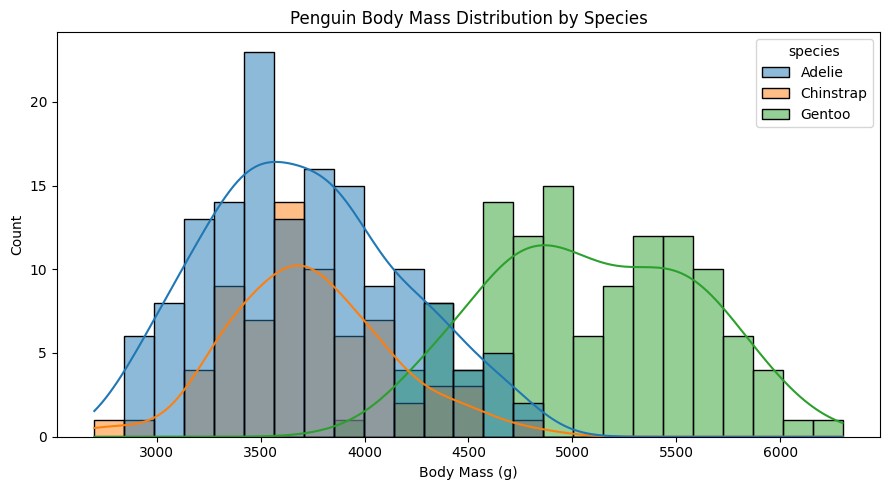

In [3]:
plt.figure(figsize=(9, 5))
sns.histplot(
    data=penguins,
    x="body_mass_g",
    hue="species",
    bins=25,
    kde=True
)
plt.title("Penguin Body Mass Distribution by Species")
plt.xlabel("Body Mass (g)")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "penguin_hist.png", dpi=150, bbox_inches="tight")
plt.show()


## 2. Compare axes-level and figure-level Seaborn APIs

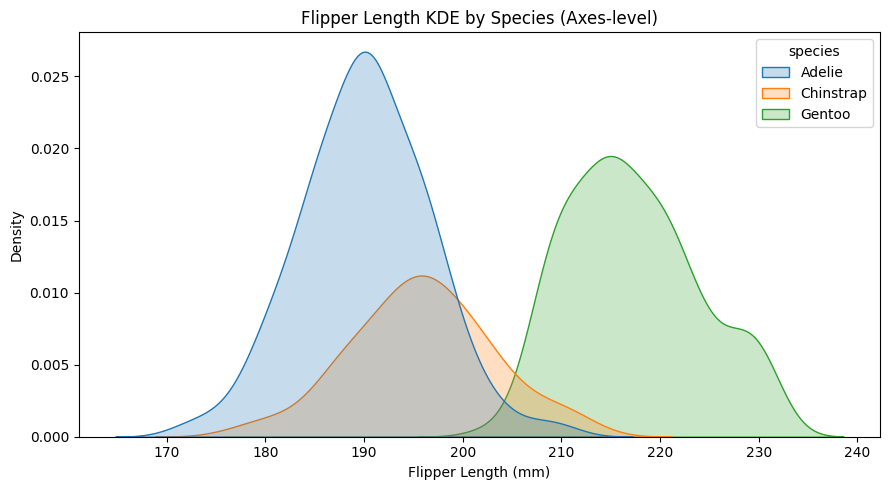

Return type from sns.kdeplot: <class 'matplotlib.axes._axes.Axes'>


In [4]:
# Axes-level function: draws on the supplied Matplotlib Axes.
fig, ax = plt.subplots(figsize=(9, 5))
axes_result = sns.kdeplot(
    data=penguins,
    x="flipper_length_mm",
    hue="species",
    fill=True,
    ax=ax
)
ax.set_title("Flipper Length KDE by Species (Axes-level)")
ax.set_xlabel("Flipper Length (mm)")
ax.set_ylabel("Density")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "flipper_axes_level.png", dpi=150, bbox_inches="tight")
plt.show()

print("Return type from sns.kdeplot:", type(axes_result))


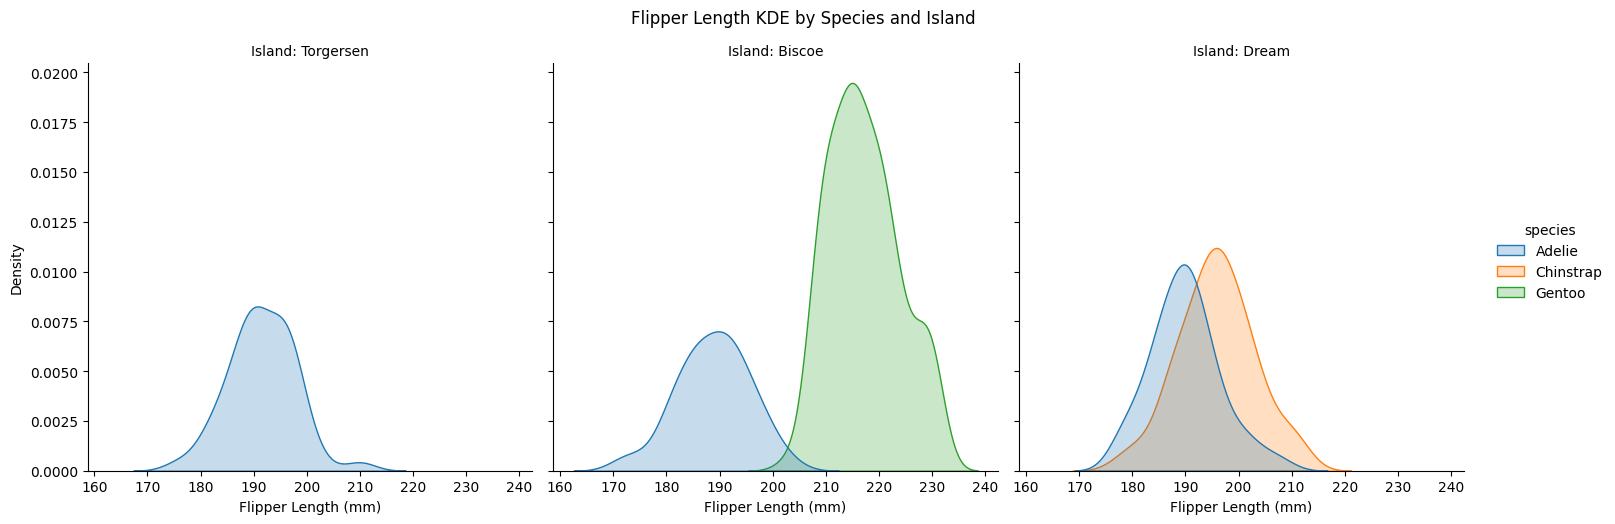

Return type from sns.displot: <class 'seaborn.axisgrid.FacetGrid'>


In [5]:
# Figure-level function: creates and manages its own FacetGrid.
figure_result = sns.displot(
    data=penguins,
    x="flipper_length_mm",
    kind="kde",
    hue="species",
    fill=True,
    col="island"
)
figure_result.set_axis_labels("Flipper Length (mm)", "Density")
figure_result.set_titles("Island: {col_name}")
figure_result.figure.suptitle("Flipper Length KDE by Species and Island", y=1.04)
figure_result.figure.savefig(
    OUTPUT_DIR / "flipper_figure_level.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

print("Return type from sns.displot:", type(figure_result))


## 3. One-row categorical plot panel

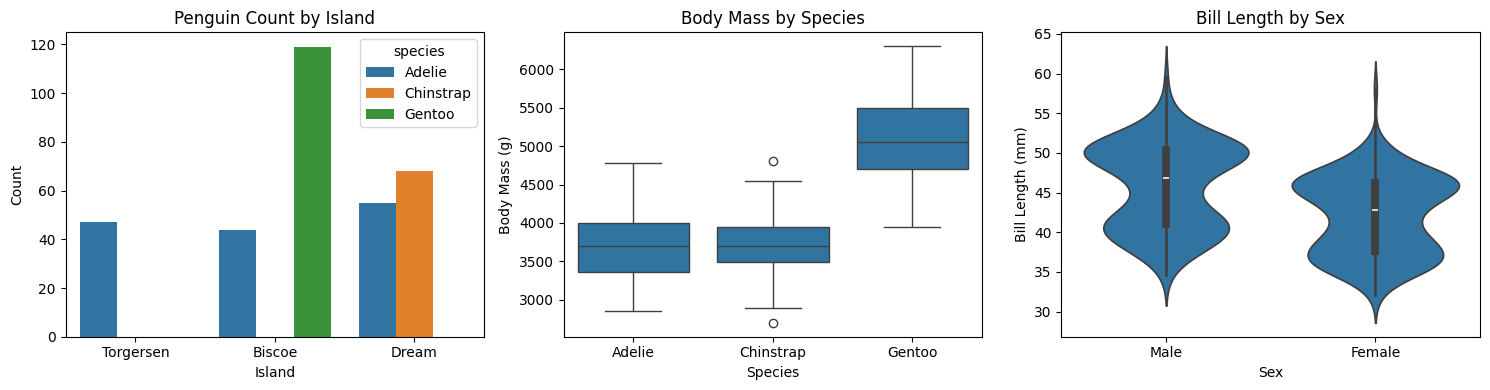

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.countplot(data=penguins, x="island", hue="species", ax=axes[0])
axes[0].set_title("Penguin Count by Island")
axes[0].set_xlabel("Island")
axes[0].set_ylabel("Count")

sns.boxplot(data=penguins, x="species", y="body_mass_g", ax=axes[1])
axes[1].set_title("Body Mass by Species")
axes[1].set_xlabel("Species")
axes[1].set_ylabel("Body Mass (g)")

sns.violinplot(data=penguins, x="sex", y="bill_length_mm", ax=axes[2])
axes[2].set_title("Bill Length by Sex")
axes[2].set_xlabel("Sex")
axes[2].set_ylabel("Bill Length (mm)")

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "penguin_categorical.png", dpi=150, bbox_inches="tight")
plt.show()


## 4. Reusable panel function: darkgrid and whitegrid

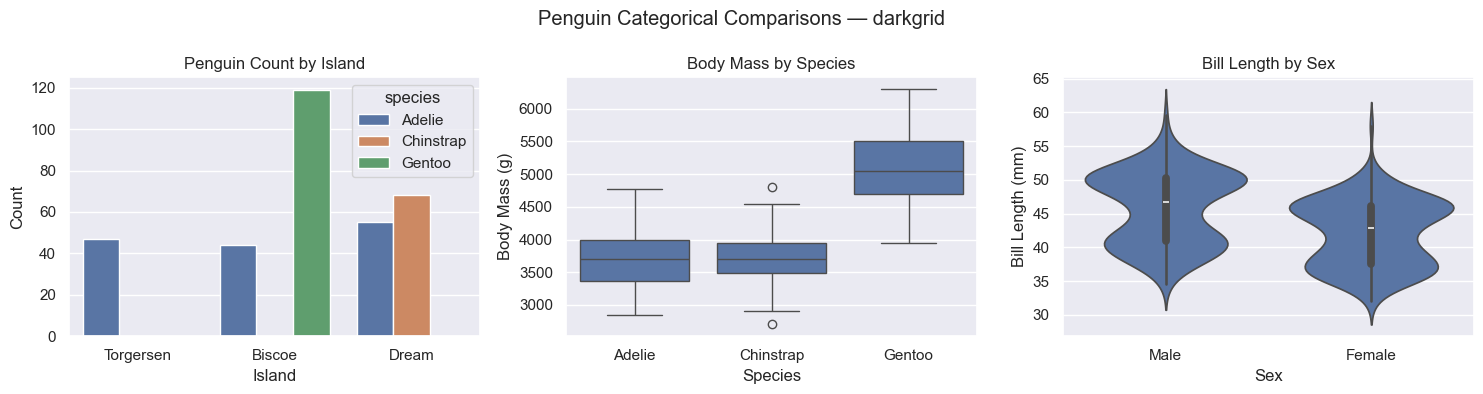

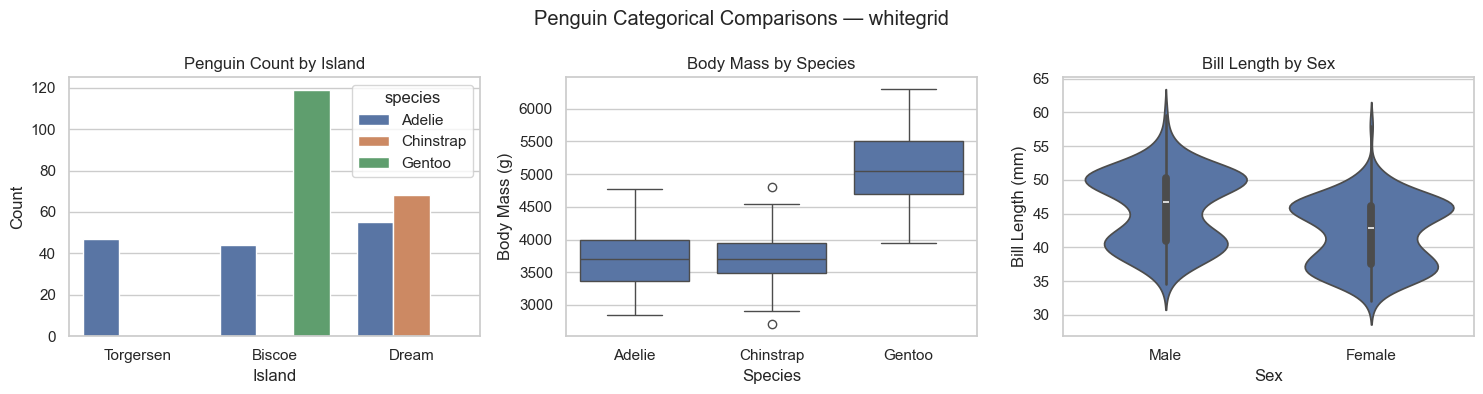

In [7]:
def make_panel(style, filename):
    sns.set_theme(style=style)

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    sns.countplot(data=penguins, x="island", hue="species", ax=axes[0])
    axes[0].set_title("Penguin Count by Island")
    axes[0].set_xlabel("Island")
    axes[0].set_ylabel("Count")

    sns.boxplot(data=penguins, x="species", y="body_mass_g", ax=axes[1])
    axes[1].set_title("Body Mass by Species")
    axes[1].set_xlabel("Species")
    axes[1].set_ylabel("Body Mass (g)")

    sns.violinplot(data=penguins, x="sex", y="bill_length_mm", ax=axes[2])
    axes[2].set_title("Bill Length by Sex")
    axes[2].set_xlabel("Sex")
    axes[2].set_ylabel("Bill Length (mm)")

    fig.suptitle(f"Penguin Categorical Comparisons — {style}")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

make_panel("darkgrid", "penguin_darkgrid.png")
make_panel("whitegrid", "penguin_whitegrid.png")


## Verify all generated image files

In [8]:
required_files = [
    "penguin_hist.png",
    "flipper_axes_level.png",
    "flipper_figure_level.png",
    "penguin_categorical.png",
    "penguin_darkgrid.png",
    "penguin_whitegrid.png"
]

for filename in required_files:
    print(f"{filename}: {Path(filename).exists()}")


penguin_hist.png: True
flipper_axes_level.png: True
flipper_figure_level.png: True
penguin_categorical.png: True
penguin_darkgrid.png: True
penguin_whitegrid.png: True
